In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('/content/Iris.csv')

In [3]:
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [4]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [5]:
# encode categorical --> Numeric

In [17]:
le = {}
df_enc = df.copy()
for col in df.columns:
  le[col] = LabelEncoder()
  df_enc[col] = le[col].fit_transform(df[col])

In [18]:
df_enc

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,0,8,14,4,1,0
1,1,6,9,4,1,0
2,2,4,11,3,1,0
3,3,3,10,5,1,0
4,4,7,15,4,1,0
...,...,...,...,...,...,...
145,145,24,9,28,19,2
146,146,20,4,26,15,2
147,147,22,9,28,16,2
148,148,19,13,30,19,2


In [9]:
# features & Target

In [36]:
X = df_enc[['Id','SepalLengthCm','SepalWidthCm','PetalLengthCm','PetalWidthCm']]
Y = df_enc['Species']

In [37]:
X

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,0,8,14,4,1
1,1,6,9,4,1
2,2,4,11,3,1
3,3,3,10,5,1
4,4,7,15,4,1
...,...,...,...,...,...
145,145,24,9,28,19
146,146,20,4,26,15
147,147,22,9,28,16
148,148,19,13,30,19


In [38]:
Y

,Species
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


In [39]:
model = CategoricalNB()
model.fit(X,Y)

CategoricalNB()

In [40]:
test = [[0,8,14,4,1]]

In [41]:
test

[[0, 8, 14, 4, 1]]

In [43]:
print("-- Prediction -----------------------")
for t in test:
        # Since the test features are already encoded integers matching X's format,
        # we pass them directly into the model as a row without transforming them again.
        row = [t]
        pred_encoded = model.predict(row)
        pred = le['Species'].inverse_transform(pred_encoded)[0]
        prob = model.predict_proba(row)[0]

        print(f"Input : Id={t[0]}, SepalLengthCm={t[1]}, SepalWidthCm={t[2]}, PetalLengthCm={t[3]}, PetalWidthCm={t[4]}")
        print(f"Result : \tSpecies -> {pred}")
        for i, class_name in enumerate(le['Species'].classes_):
            print(f"P({class_name}) = {prob[i]:.4f}")

-- Prediction -----------------------
Input : Id=0, SepalLengthCm=8, SepalWidthCm=14, PetalLengthCm=4, PetalWidthCm=1
Result : 	Species -> Iris-setosa
P(Iris-setosa) = 0.9999
P(Iris-versicolor) = 0.0000
P(Iris-virginica) = 0.0000


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [44]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X)
print(f"\nTraining Accuracy : {accuracy_score(Y, y_pred)*100:.2f}%")


Training Accuracy : 97.33%


In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/tmp/ipykernel_3247/1014348131.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Species', y='SepalLengthCm', ax=axes[1, 0], palette='Set2')
/tmp/ipykernel_3247/1014348131.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Species', y='PetalLengthCm', ax=axes[1, 1], palette='Set2')


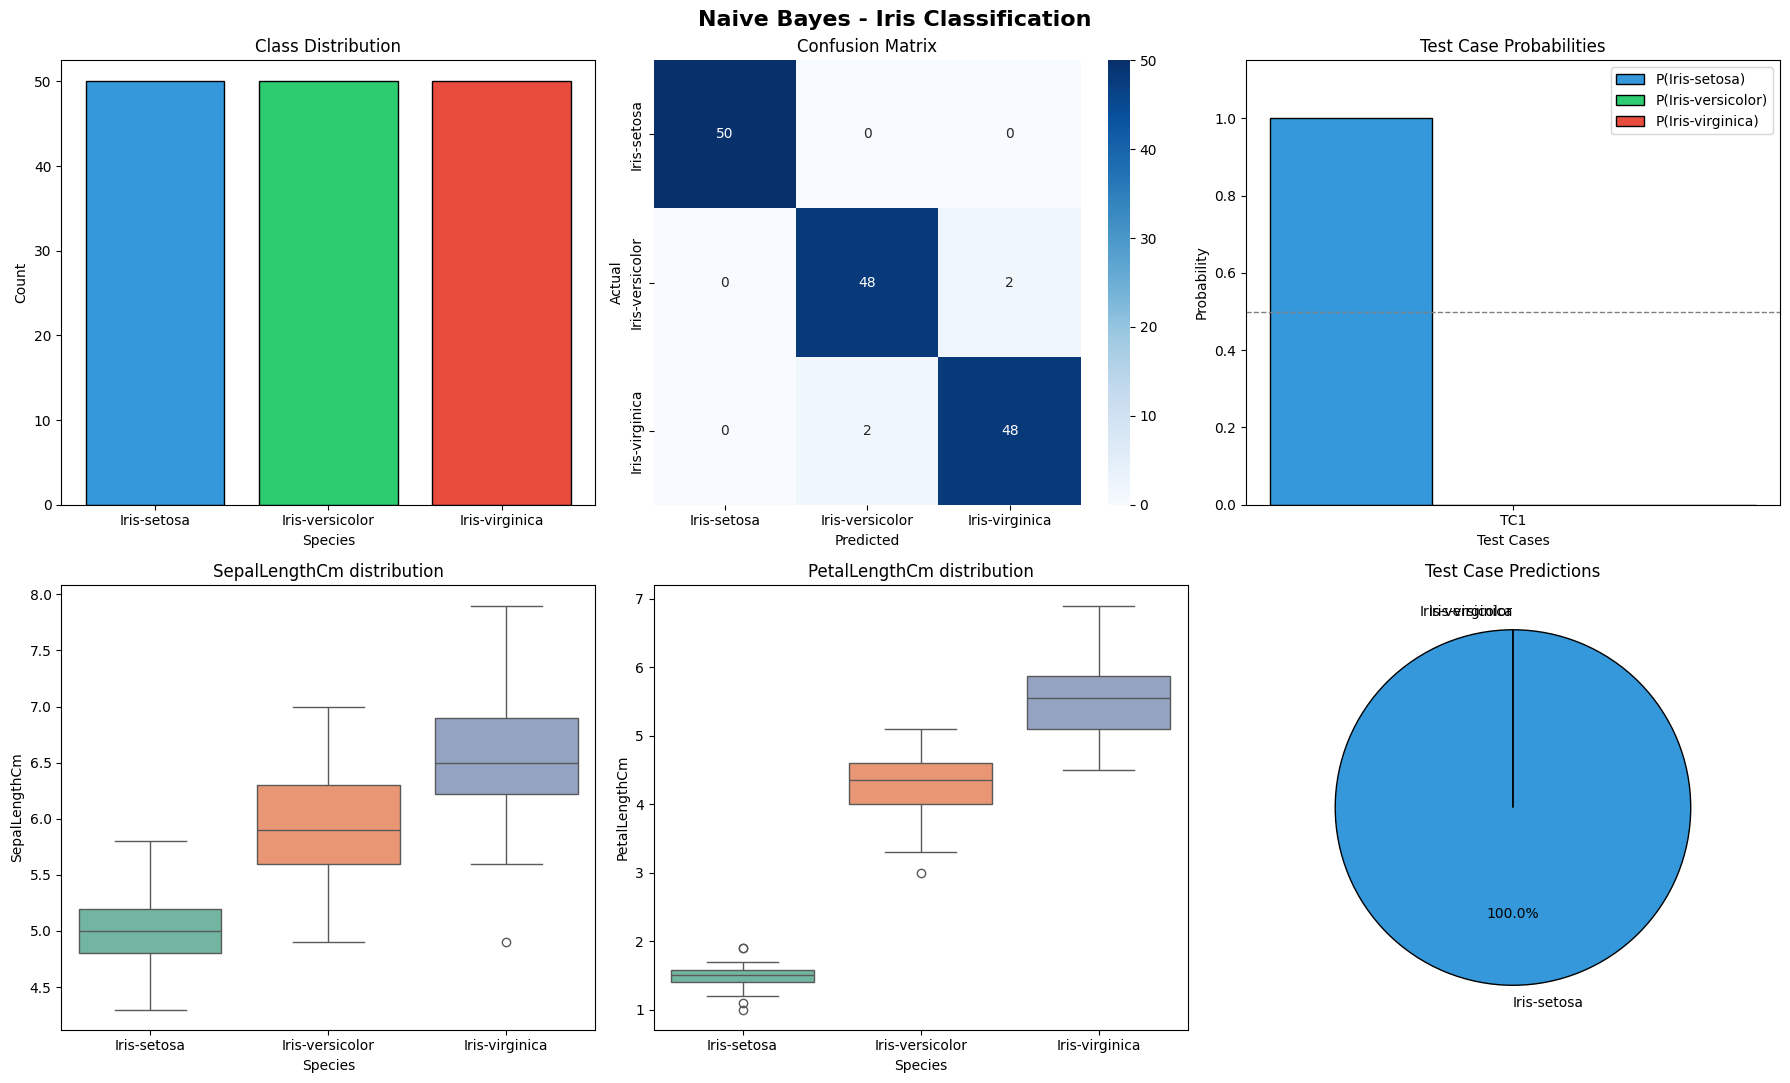

In [47]:
# Pre-calculate variables for the test predictions so the plots work
test_cases = test
class_names = list(le['Species'].classes_)

# Initialize dictionary to track probabilities dynamically for each class
probs_history = {name: [] for name in class_names}
predictions = []

for t in test_cases:
    # Since the test features are already encoded integers matching X's format,
    # we pass them directly into the model as a row without transforming them again.
    row_data = [t]
    prob = model.predict_proba(row_data)[0]
    pred_encoded = model.predict(row_data)[0]
    pred = le['Species'].inverse_transform([pred_encoded])[0]

    for idx, name in enumerate(class_names):
        probs_history[name].append(prob[idx])
    predictions.append(pred)

# --Plots------
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Naive Bayes - Iris Classification", fontsize=16, fontweight='bold')

# 1. Class Distribution
counts = df['Species'].value_counts()
axes[0, 0].bar(counts.index, counts.values, color=['#3498db', '#2ecc71', '#e74c3c'], edgecolor='black')
axes[0, 0].set_title('Class Distribution')
axes[0, 0].set_xlabel('Species')
axes[0, 0].set_ylabel('Count')

# 2. Confusion Matrix
cm = confusion_matrix(Y, model.predict(X))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0, 1])
axes[0, 1].set_title('Confusion Matrix')
axes[0, 1].set_xlabel('Predicted')
axes[0, 1].set_ylabel('Actual')

# 3. Prediction Probabilities (Group Bar for Multi-Class)
tc_labels = [f"TC{i+1}" for i in range(len(test_cases))]
x_pos = np.arange(len(tc_labels))
w = 0.25
colors_list = ['#3498db', '#2ecc71', '#e74c3c']

for idx, name in enumerate(class_names):
    axes[0, 2].bar(x_pos + (idx - 1) * w, probs_history[name], w, label=f'P({name})', color=colors_list[idx], edgecolor='black')

axes[0, 2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0, 2].set_title("Test Case Probabilities")
axes[0, 2].set_xlabel('Test Cases')
axes[0, 2].set_xticks(x_pos)
axes[0, 2].set_xticklabels(tc_labels)
axes[0, 2].set_ylabel('Probability')
axes[0, 2].set_ylim(0, 1.15)
axes[0, 2].legend()

# 4. Boxplot - SepalLengthCm vs Species
sns.boxplot(data=df, x='Species', y='SepalLengthCm', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('SepalLengthCm distribution')
axes[1, 0].set_xlabel('Species')
axes[1, 0].set_ylabel('SepalLengthCm')

# 5. Boxplot - PetalLengthCm vs Species
sns.boxplot(data=df, x='Species', y='PetalLengthCm', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('PetalLengthCm distribution')
axes[1, 1].set_xlabel('Species')
axes[1, 1].set_ylabel('PetalLengthCm')

# 6. Pie Chart - Final Predictions
pred_counts = pd.Series(predictions).value_counts().reindex(class_names, fill_value=0)
axes[1, 2].pie(pred_counts.values, labels=pred_counts.index, colors=colors_list, autopct=lambda p: '{:.1f}%'.format(p) if p > 0 else '', startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1, 2].set_title('Test Case Predictions')

plt.tight_layout()
plt.show()